In [ ]:
import torch

In [88]:
"""
A fully-connected ReLU network with one hidden layer, trained to predict y from x
by minimizing squared Euclidean distance.
This implementation uses the nn package from PyTorch to build the network.
PyTorch autograd makes it easy to define computational graphs and take gradients,
but raw autograd can be a bit too low-level for defining complex neural networks;
this is where the nn package can help. The nn package defines a set of Modules,
which you can think of as a neural network layer that has produces output from
input and may have some trainable weights or other state.
"""

device = torch.device('cpu')
# device = torch.device('cuda') # Uncomment this to run on GPU

# N is batch size; D_in is input dimension;
# H is hidden dimension; D_out is output dimension.
N, D_in, H, D_out = 1000, 2, 70, 1

# Create random Tensors to hold inputs and outputs
x = torch.randn(N, D_in, device=device)
theta = torch.randn(D_in, D_out, device=device)

y = torch.pow(x @ theta, 2)

# Use the nn package to define our model as a sequence of layers. nn.Sequential
# is a Module which contains other Modules, and applies them in sequence to
# produce its output. Each Linear Module computes output from input using a
# linear function, and holds internal Tensors for its weight and bias.
# After constructing the model we use the .to() method to move it to the
# desired device.
model = torch.nn.Sequential(
          torch.nn.Linear(D_in, H),
          torch.nn.ReLU(),
          torch.nn.Linear(H, D_out),
        ).to(device)

# The nn package also contains definitions of popular loss functions; in this
# case we will use Mean Squared Error (MSE) as our loss function. Setting
# reduction='sum' means that we are computing the *sum* of squared errors rather
# than the mean; this is for consistency with the examples above where we
# manually compute the loss, but in practice it is more common to use mean
# squared error as a loss by setting reduction='elementwise_mean'.
loss_fn = torch.nn.MSELoss(reduction='sum')

learning_rate = 4e-4
for n in range(1000):
    for t in range(int(n/2) + 100):
      # Forward pass: compute predicted y by passing x to the model. Module objects
      # override the __call__ operator so you can call them like functions. When
      # doing so you pass a Tensor of input data to the Module and it produces
      # a Tensor of output data.
        y_pred = model(x[:n])

      # Compute and print loss. We pass Tensors containing the predicted and true
      # values of y, and the loss function returns a Tensor containing the loss.
        loss = loss_fn(y_pred, y[:n])
        if t == int(n/2) + 100 - 1:
            print(t, loss.item())

      # Zero the gradients before running the backward pass.
        model.zero_grad()

      # Backward pass: compute gradient of the loss with respect to all the learnable
      # parameters of the model. Internally, the parameters of each Module are stored
      # in Tensors with requires_grad=True, so this call will compute gradients for
      # all learnable parameters in the model.
        loss.backward()

      # Update the weights using gradient descent. Each parameter is a Tensor, so
      # we can access its data and gradients like we did before.
        with torch.no_grad():
            for param in model.parameters():
                param.data -= learning_rate * param.grad

99 0.0
99 0.4043615460395813
100 1.652982473373413
100 1.895257830619812
101 3.783051013946533
101 3.093736171722412
102 2.6327061653137207
102 2.7491040229797363
103 3.36914324760437
103 2.7566356658935547
104 1.3520456552505493
104 1.967525839805603
105 0.8842581510543823
105 0.536280632019043
106 0.40383028984069824
106 0.4030781090259552
107 3.2423481941223145
107 5.899957180023193
108 4.7864532470703125
108 3.99460768699646
109 3.2351694107055664
109 2.66520357131958
110 3.285890817642212
110 2.293670654296875
111 2.670210361480713
111 2.584376811981201
112 1.9210848808288574
112 1.5287283658981323
113 1.2547533512115479
113 1.1226614713668823
114 1.8395968675613403
114 1.331399917602539
115 0.9600874185562134
115 0.6857339143753052
116 0.5145365595817566
116 0.4162788391113281
117 0.3469865024089813
117 0.29632577300071716
118 0.250912070274353
118 0.21368218958377838
119 0.18785037100315094
119 2.1047871112823486
120 1.5548546314239502
120 1.3905888795852661
121 1.13138151168823

274 0.5652165412902832
275 0.7249423265457153
275 0.3339150846004486
276 0.7344704866409302
276 0.5780322551727295
277 0.3523457646369934
277 1.0656640529632568
278 0.2666241228580475
278 0.41114041209220886
279 0.18254628777503967
279 0.17752397060394287
280 1.8527265787124634
280 0.2210395783185959
281 0.16916099190711975
281 2.8065361976623535
282 0.22258350253105164
282 0.32607588171958923
283 1.4708815813064575
283 0.4001855254173279
284 0.3847898542881012
284 1.0287141799926758
285 0.23421722650527954
285 0.6478563547134399
286 0.6300886273384094
286 0.2758478820323944
287 0.80836021900177
287 0.189304918050766
288 0.14877642691135406
288 0.26119810342788696
289 1.0498995780944824
289 0.33588534593582153
290 0.7797227501869202
290 0.3039184510707855
291 0.24887114763259888
291 1.2121387720108032
292 0.312380850315094
292 0.33495083451271057
293 1.1730589866638184
293 0.30882105231285095
294 0.5182474255561829
294 0.7999341487884521
295 0.30820393562316895
295 0.6734625101089478
2

454 189.65846252441406
455 190.06405639648438
455 192.10464477539062
456 264.9955749511719
456 198.3621368408203
457 200.62860107421875
457 207.58615112304688
458 296.64654541015625
458 215.26025390625
459 215.43722534179688
459 215.08078002929688
460 297.0263977050781
460 216.51316833496094
461 217.22113037109375
461 223.7132110595703
462 311.26556396484375
462 225.28652954101562
463 230.09950256347656
463 240.2929229736328
464 345.7229919433594
464 245.7960205078125
465 245.84104919433594
465 256.2516174316406
466 362.87786865234375
466 260.3902282714844
467 273.5506896972656
467 274.8008117675781
468 396.28564453125
468 276.75823974609375
469 277.08551025390625
469 282.17633056640625
470 408.27630615234375
470 292.30792236328125
471 292.17376708984375
471 292.58428955078125
472 422.9477233886719
472 296.1125793457031
473 297.0608215332031
473 312.03472900390625
474 467.4941101074219
474 319.543701171875
475 321.552001953125
475 322.4937438964844
476 476.440185546875
476 325.47915649

In [145]:

"""
A fully-connected ReLU network with one hidden layer, trained to predict y from x
by minimizing squared Euclidean distance.
This implementation uses the nn package from PyTorch to build the network.
Rather than manually updating the weights of the model as we have been doing,
we use the optim package to define an Optimizer that will update the weights
for us. The optim package defines many optimization algorithms that are commonly
used for deep learning, including SGD+momentum, RMSProp, Adam, etc.
"""

# N is batch size; D_in is input dimension;
# H is hidden dimension; D_out is output dimension.
N, D_in, H, D_out = 1000, 2, 10, 1

# Create random Tensors to hold inputs and outputs.
x = torch.randn(N, D_in, device=device)
theta = torch.randn(D_in, D_out, device=device)

y = torch.pow(x @ theta, 2)

# Use the nn package to define our model and loss function.
model = torch.nn.Sequential(
          torch.nn.Linear(D_in, H),
          torch.nn.ReLU(),
          torch.nn.Linear(H, D_out),
        )
loss_fn = torch.nn.MSELoss(reduction='sum')

# Use the optim package to define an Optimizer that will update the weights of
# the model for us. Here we will use Adam; the optim package contains many other
# optimization algoriths. The first argument to the Adam constructor tells the
# optimizer which Tensors it should update.
learning_rate = 8e-4
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
for t in range(500):
  # Forward pass: compute predicted y by passing x to the model.
    y_pred = model(x)

  # Compute and print loss.
    loss = loss_fn(y_pred, y)
    #print(t, loss.item())
  
  # Before the backward pass, use the optimizer object to zero all of the
  # gradients for the Tensors it will update (which are the learnable weights
  # of the model)
    optimizer.zero_grad()

  # Backward pass: compute gradient of the loss with respect to model parameters
    loss.backward()

  # Calling the step function on an Optimizer makes an update to its parameters
    optimizer.step()
print(t, loss.item())

499 3770.4794921875


In [249]:
"""
A fully-connected ReLU network with one hidden layer, trained to predict y from x
by minimizing squared Euclidean distance.
This implementation defines the model as a custom Module subclass. Whenever you
want a model more complex than a simple sequence of existing Modules you will
need to define your model this way.
"""

class TwoLayerNet(torch.nn.Module):
    def __init__(self, D_in, H, D_out):
    
        """
        In the constructor we instantiate two nn.Linear modules and assign them as
        member variables.
        """
        super(TwoLayerNet, self).__init__()
        self.linear1 = torch.nn.Linear(D_in, H)
        self.linear2 = torch.nn.Linear(H, D_out)

    def forward(self, x):
        """
        In the forward function we accept a Tensor of input data and we must return
        a Tensor of output data. We can use Modules defined in the constructor as
        well as arbitrary (differentiable) operations on Tensors.
        """
        h_relu = self.linear1(x).clamp(min=0)
        y_pred = self.linear2(h_relu)
        return y_pred
    
def train_model(model,
    x,
    y,
    num_epochs=500,
    #batch_size,
    learning_rate=4e-4,
    lr_decay=1,
    device = torch.device("cpu"),
    print_loss=False
):
    loss_fn = torch.nn.MSELoss(reduction='sum')
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    lr_scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda epoch: lr_decay ** epoch
    )
    for t in range(num_epochs):
      # Forward pass: Compute predicted y by passing x to the model
        y_pred = model(x)

      # Compute and print loss
        loss = loss_fn(y_pred, y)
        if print_loss:
            print(t, loss.item())

      # Zero gradients, perform a backward pass, and update the weights.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        #lr_scheduler.step()
    #print(loss.item())

# N is batch size; D_in is input dimension;
# H is hidden dimension; D_out is output dimension.
N, D_in, H, D_out = 1000, 2, 10, 1

# Create random Tensors to hold inputs and outputs
x = torch.randn(N, D_in, device=device)
theta = torch.randn(D_in, D_out, device=device)
y = torch.pow(x @ theta, 1)

# Construct our model by instantiating the class defined above.
model = TwoLayerNet(D_in, H, D_out)

# Construct our loss function and an Optimizer. The call to model.parameters()
# in the SGD constructor will contain the learnable parameters of the two
# nn.Linear modules which are members of the model.


In [250]:
for n in range(100):
    train_model(
        model,
        x[:n],
        y[:n],
        learning_rate=1e-3,
        num_epochs=500,
    )

In [251]:
with torch.no_grad():
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
loss

tensor(0.0100)

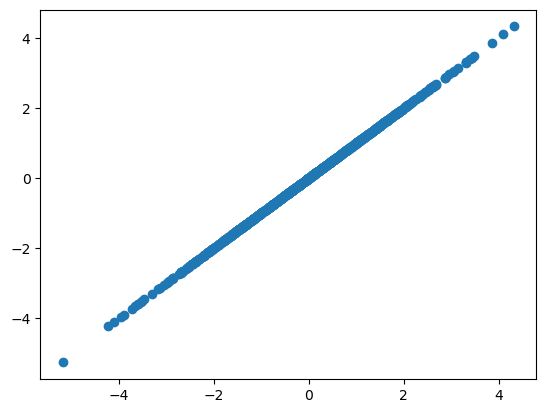

In [252]:
plt.scatter(y_pred, y)

0 nan
1 nan
2 nan
3 nan
4 nan
5 nan
6 nan
7 nan
8 nan
9 nan
10 nan
11 nan
12 nan
13 nan
14 nan
15 nan
16 nan
17 nan
18 nan
19 nan
20 nan
21 nan
22 nan
23 nan
24 nan
25 nan
26 nan
27 nan
28 nan
29 nan
30 nan
31 nan
32 nan
33 nan
34 nan
35 nan
36 nan
37 nan
38 nan
39 nan
40 nan
41 nan
42 nan
43 nan
44 nan
45 nan
46 nan
47 nan
48 nan
49 nan
50 nan
51 nan
52 nan
53 nan
54 nan
55 nan
56 nan
57 nan
58 nan
59 nan
60 nan
61 nan
62 nan
63 nan
64 nan
65 nan
66 nan
67 nan
68 nan
69 nan
70 nan
71 nan
72 nan
73 nan
74 nan
75 nan
76 nan
77 nan
78 nan
79 nan
80 nan
81 nan
82 nan
83 nan
84 nan
85 nan
86 nan
87 nan
88 nan
89 nan
90 nan
91 nan
92 nan
93 nan
94 nan
95 nan
96 nan
97 nan
98 nan
99 nan
100 nan
101 nan
102 nan
103 nan
104 nan
105 nan
106 nan
107 nan
108 nan
109 nan
110 nan
111 nan
112 nan
113 nan
114 nan
115 nan
116 nan
117 nan
118 nan
119 nan
120 nan
121 nan
122 nan
123 nan
124 nan
125 nan
126 nan
127 nan
128 nan
129 nan
130 nan
131 nan
132 nan
133 nan
134 nan
135 nan
136 nan
137 nan
138 na

In [23]:
theta.shape

torch.Size([1000])

In [89]:
with torch.no_grad():
    y_hat = model(x)

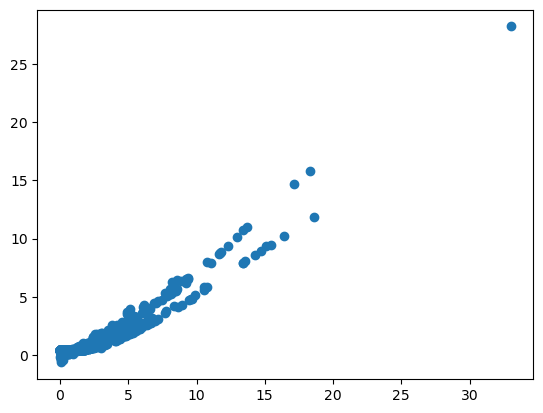

In [90]:
import matplotlib.pyplot as plt
plt.scatter(y, y_hat)